# Segmentação dos assinantes · Vitaliza · grupo 11

**Pergunta:** quem são os assinantes, em grupos que qualquer área entenda, e quais deles pedem ação?

**Base:** os 14.032 assinantes de 31/07/2026 da `base_analitica.csv` (EDA em `notebooks/eda_churn.ipynb`).
**Regra do enunciado:** o agrupamento não usa a informação de quem saiu. O churn entra só depois, para medir os grupos.

**Ficam fora do agrupamento, de propósito:** `churn_60d`; renovação desligada e cancelamento pelo site
(decisão já tomada: entram na priorização); valor mensal (eixo de valor da matriz valor × risco);
idade, sexo, canal e UF (só descrevem).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from segmentacao import (SEGMENTOS, VARIAVEIS, ajustar, avaliar_k, camada_comportamento,  # noqa: E402
                         gemeo_demografico, matriz, nomear_clusters, perfil, preparar, segmento)

PROCESSADOS = RAIZ / "dados" / "processados"
GRAFICOS = RAIZ / "saidas" / "graficos"
AZUL, LARANJA, AQUA, AMARELO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c3c2b7"
SUPERFICIE, TEXTO, TEXTO_2, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
COR_SEG = dict(zip(SEGMENTOS, [LARANJA, AZUL, AQUA, AMARELO]))
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": TEXTO_2, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "font.size": 10,
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.titlecolor": TEXTO,
})
pct = lambda v, casas=1: f"{100 * v:.{casas}f}%".replace(".", ",")

b = preparar(pd.read_csv(PROCESSADOS / "base_analitica.csv", parse_dates=["inicio", "fim"]))
CHURN_BASE = b["churn_60d"].mean()
print(f"{len(b)} assinantes | churn_60d {pct(CHURN_BASE, 2)} | variáveis do agrupamento: {VARIAVEIS}")
display(b[VARIAVEIS].describe().round(2))

14032 assinantes | churn_60d 10,47% | variáveis do agrupamento: ['log_treinos_mes', 'tendencia_uso', 'pct_ar_livre_k', 'log_tempo_casa', 'meses_ate_renovacao', 'plano_anual']


,log_treinos_mes,tendencia_uso,pct_ar_livre_k,log_tempo_casa,meses_ate_renovacao,plano_anual
count,14032.00,14032.00,14032.00,14032.00,14032.00,14032.00
mean,1.60,0.93,0.53,2.19,3.24,0.59
std,0.90,0.51,0.36,1.03,3.75,0.49
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.92,0.67,0.12,1.61,0.00,0.00
50%,1.67,1.00,0.75,2.30,1.00,1.00
75%,2.34,1.14,0.79,2.89,6.00,1.00
max,3.97,2.00,1.00,4.28,11.00,1.00


## 1. Variáveis do agrupamento

| Variável | Por quê | Transformação |
|---|---|---|
| `log_treinos_mes` | principal medida de uso; resume sessões, dias ativos e minutos (correlação 0,93–0,99) | log(1 + treinos por mês) |
| `tendencia_uso` | queda de uso (julho contra a média de maio e junho) | razão limitada a 0–2; 1 para quem tem menos de 3 meses |
| `pct_ar_livre_k` | perfil de treino (ar livre × vídeo), orienta a mensagem | 0–1; 0,5 para quem não treinou |
| `log_tempo_casa` | ciclo de vida | log(1 + meses) |
| `meses_ate_renovacao` | no anual, o risco está na data de renovação (informação de calendário conhecida em 31/07) | 0–11 no anual; 0 no mensal |
| `plano_anual` | maior divisor de risco | 0/1 |

Todas padronizadas (média 0, desvio 1) antes do k-means.

## 2. Quantos grupos: as quatro lentes (inércia, silhueta, estabilidade, negócio)

,k,inercia,silhueta,estabilidade_ari,ari_min
0,3,52980.0,0.247,0.992,0.980
1,4,47184.0,0.230,0.984,0.973
2,5,42102.0,0.240,0.869,0.604
3,6,38131.0,0.248,0.839,0.693
4,7,34995.0,0.263,0.890,0.730


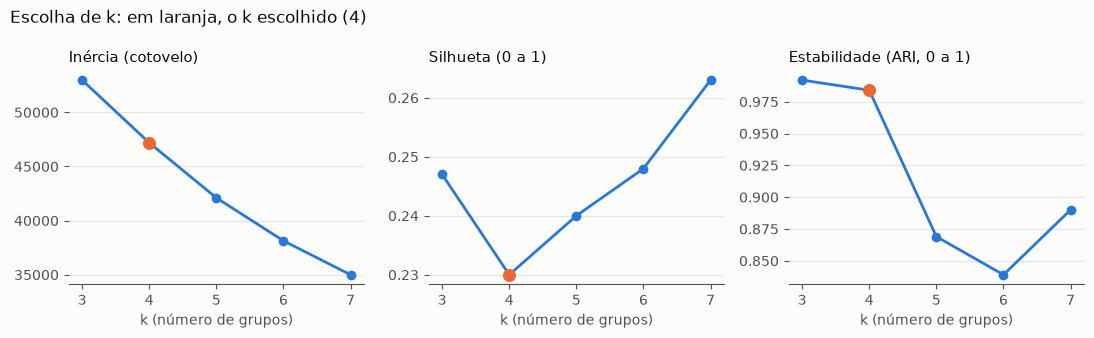

In [2]:
X, escala = matriz(b)
lentes = avaliar_k(X, range(3, 8))
display(lentes)
lentes.to_csv(RAIZ / "saidas" / "seg_escolha_k.csv", index=False)

fig, eixos = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col, titulo in zip(eixos, ["inercia", "silhueta", "estabilidade_ari"],
                           ["Inércia (cotovelo)", "Silhueta (0 a 1)", "Estabilidade (ARI, 0 a 1)"]):
    ax.plot(lentes["k"], lentes[col], color=AZUL, marker="o", linewidth=2, markersize=6)
    ax.scatter([4], lentes.loc[lentes["k"] == 4, col], color=LARANJA, s=70, zorder=3)
    ax.set_title(titulo, fontsize=10.5)
    ax.set_xticks(lentes["k"])
    ax.set_xlabel("k (número de grupos)")
fig.suptitle("Escolha de k: em laranja, o k escolhido (4)", x=0.01, ha="left", fontsize=12, color=TEXTO)
fig.tight_layout()
fig.savefig(GRAFICOS / "09_seg_escolha_k.png", dpi=150)
plt.show()

**Leitura.** Nenhum k separa bem: a silhueta fica entre 0,23 e 0,26 para k de 3 a 7, uma separação fraca, como a da aula (0,22). O cotovelo da inércia não tem quebra clara. Por isso, a escolha foi pela **estabilidade** e pelo **negócio**. k = 3 e k = 4 são os únicos estáveis (ARI de 0,99 e 0,98: os grupos se repetem em amostras diferentes). De k = 5 em diante, o ARI cai para 0,84–0,89, com piores casos de 0,60 a 0,73. Entre 3 e 4, o k = 4 separa o mensal em dois perfis de treino, útil para a mensagem. O k = 4 tem a menor silhueta da faixa (0,23 contra 0,25 no k = 3), e essa é a troca que aceitamos.

## 3. Os 4 grupos do k-means e o churn de cada um (medido depois)

In [3]:
km = ajustar(X, 4)
b["cluster"] = nomear_clusters(b, km.labels_)
centros = pd.DataFrame(escala.inverse_transform(km.cluster_centers_), columns=VARIAVEIS)
centros.index = pd.Series(range(4)).map(dict(zip(km.labels_, b["cluster"]))).fillna("?")
display(centros.round(2))
p_cluster = perfil(b, "cluster").sort_values("churn", ascending=False)
display(p_cluster[["n", "pct_base", "churn", "pct_do_churn", "treinos_mes", "pct_ar_livre", "pct_mensal",
                   "meses_ate_renovacao", "renovacao_desligada", "valor_mensal"]].round(3))

,log_treinos_mes,tendencia_uso,pct_ar_livre_k,log_tempo_casa,meses_ate_renovacao,plano_anual
anual pouco uso,0.67,0.75,0.60,2.73,3.83,1.00
mensal ar livre,1.87,0.99,0.82,1.90,-0.00,0.00
mensal vídeo,1.87,1.00,0.08,2.02,0.01,0.03
anual ativo,2.10,1.01,0.50,2.02,7.13,1.00


,n,pct_base,churn,pct_do_churn,treinos_mes,pct_ar_livre,pct_mensal,meses_ate_renovacao,renovacao_desligada,valor_mensal
cluster,,,,,,,,,,
mensal ar livre,3283,0.234,0.164,0.367,6.00,0.818,1.000,0.000,0.046,35.402
anual pouco uso,3949,0.281,0.150,0.403,0.67,0.637,0.002,3.825,0.442,21.762
mensal vídeo,2543,0.181,0.124,0.214,6.00,0.080,0.967,0.005,0.035,35.023
anual ativo,4257,0.303,0.005,0.016,8.00,0.504,0.000,7.134,0.084,21.600


**Leitura.** O algoritmo achou quatro grupos com nome claro. O **anual com pouco uso** (3.949; 0,7 treino por mês; 44% com a renovação desligada) e o **anual ativo** (4.257; 8 treinos por mês) separam o anual pelo uso. O **mensal ao ar livre** (3.283) e o **mensal em vídeo** (2.543) separam o mensal pelo perfil de treino, com o mesmo uso (6 treinos por mês). Medido depois, o churn vai de 0,5% (anual ativo) a 16,4% (mensal ao ar livre). Quem dá nome e sentido aos grupos é o grupo, não o algoritmo.

## 4. K-means × regras simples

Regras: plano × renovação na janela (anual) × tempo de casa (mensal). Quanto cada esquema separa o churn
(AUC usando o churn do próprio grupo como score; 0,50 = acaso).

In [4]:
b["segmento"] = segmento(b)
b["camada"] = camada_comportamento(b, b["cluster"])
b["seg_camada"] = b["segmento"] + " | " + b["camada"]
comparacao = pd.DataFrame([
    (nome, b[col].nunique(), roc_auc_score(b["churn_60d"], b.groupby(col)["churn_60d"].transform("mean")))
    for nome, col in [("k-means (k = 4)", "cluster"), ("regras (4 segmentos)", "segmento"),
                      ("segmentos + camada do k-means", "seg_camada")]],
    columns=["esquema", "grupos", "auc"]).round(3)
display(comparacao)
display(pd.crosstab(b["cluster"], b["segmento"], values=b["churn_60d"], aggfunc="mean").map(lambda v: "" if pd.isna(v) else pct(v)))
display(pd.crosstab(b["cluster"], b["segmento"]))

,esquema,grupos,auc
0,k-means (k = 4),4,0.682
1,regras (4 segmentos),4,0.853
2,segmentos + camada do k-means,8,0.865


segmento,A · Anual na porta da renovação,B · Mensal novato,C · Mensal veterano,D · Anual com renovação distante
cluster,,,,
anual ativo,"9,9%",,,"0,1%"
anual pouco uso,"54,5%",,"33,3%","0,2%"
mensal ar livre,"0,0%","21,4%","12,0%",
mensal vídeo,"14,1%","14,6%","10,5%",


segmento,A · Anual na porta da renovação,B · Mensal novato,C · Mensal veterano,D · Anual com renovação distante
cluster,,,,
anual ativo,203,0,0,4054
anual pouco uso,1073,0,6,2870
mensal ar livre,1,1553,1729,0
mensal vídeo,85,1098,1360,0


**Leitura.** As regras simples separam muito mais o churn que o k-means: AUC de 0,85 contra 0,68. O k-means não enxerga **quando** o anual pode sair. O anual só sai na renovação, e a renovação na janela é uma regra de calendário, não uma distância entre clientes. Mas o k-means acrescenta o **quem**: entre os anuais que renovam em até 1 mês, quem usa pouco sai 54,5% e quem é ativo, 9,9%. No mensal novato, ar livre sai 21,4% e vídeo, 14,6%. Por isso, a segmentação final combina as duas: regras para o momento de risco e a camada do k-means para o comportamento e a mensagem (AUC de 0,87 combinadas).

## 5. Os 4 segmentos finais

,n,pct_base,churn,churn_resto,diferenca_pp,pct_do_churn,gemeo_demografico,valor_mensal,receita_anual_em_risco,renov_desligada_n,treinos_mes,tempo_casa_mediana,idade
segmento,,,,,,,,,,,,,
A · Anual na porta da renovação,1362,0.097,0.453,0.067,38.576,0.420,0.067,21.823,161501.76,554,1.33,11.0,47.0
B · Mensal novato,2651,0.189,0.186,0.086,9.975,0.335,0.087,35.445,209994.00,126,5.67,2.0,46.0
C · Mensal veterano,3095,0.221,0.114,0.102,1.160,0.240,0.102,35.431,150633.12,111,6.33,13.0,46.0
D · Anual com renovação distante,6924,0.493,0.001,0.206,-20.439,0.005,0.206,21.640,1979.04,1556,3.50,8.0,47.0


n  churn  saidas  valor_mensal  \
segmento                         camada                                         
A · Anual na porta da renovação  ativo       289  0.111      32        21.865   
                                 pouco uso  1073  0.545     585        21.812   
B · Mensal novato                ar livre   1553  0.214     332        35.375   
                                 vídeo      1098  0.146     160        35.543   
C · Mensal veterano              ar livre   1735  0.120     209        35.430   
                                 vídeo      1360  0.105     143        35.431   
D · Anual com renovação distante ativo      4054  0.001       3        21.585   
                                 pouco uso  2870  0.002       5        21.717   

                                            renov_desligada  
segmento                         camada                      
A · Anual na porta da renovação  ativo                0.042  
                                 pouco uso            0.505  
B · Mensal novato                ar livre             0.057  
                                 vídeo                0.034  
C · Mensal veterano              ar livre             0.037  
                                 vídeo                0.035  
D · Anual com renovação distante ativo                0.087  
                                 pouco uso            0.419

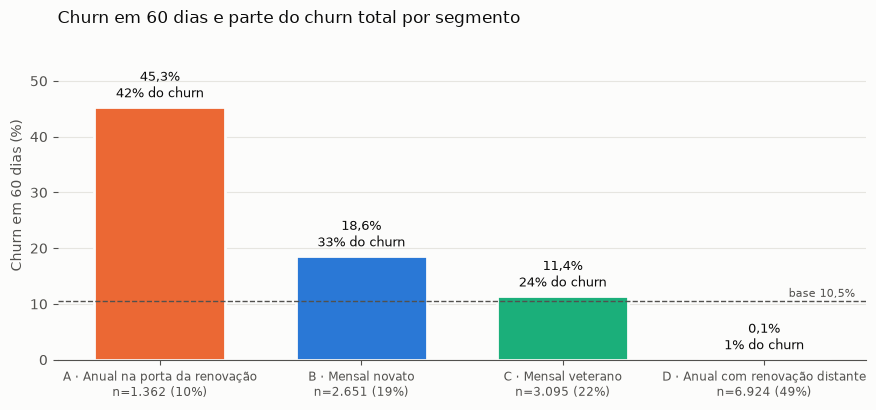

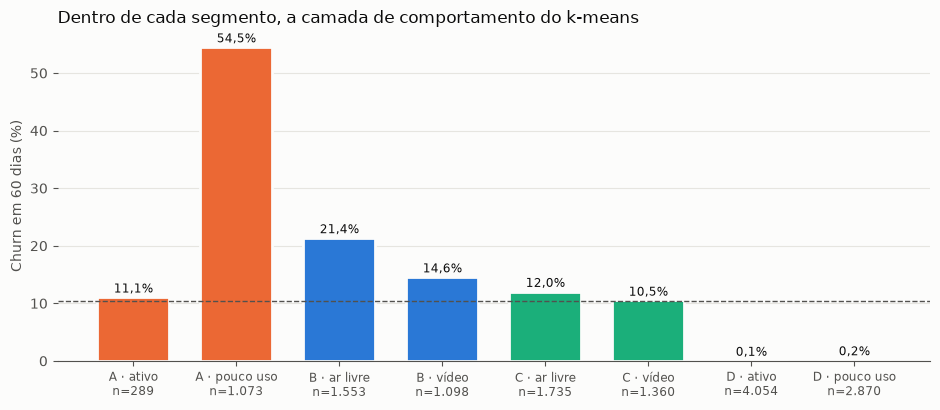

In [5]:
p_seg = perfil(b, "segmento").reindex(SEGMENTOS)
p_seg["gemeo_demografico"] = [gemeo_demografico(b, "segmento", s) for s in SEGMENTOS]
p_seg["saidas_renov_desligada"] = b[b["churn_60d"] == 1].groupby("segmento")["renovacao_desligada_ref"].sum().reindex(SEGMENTOS)
p_seg["renov_desligada_n"] = b.groupby("segmento")["renovacao_desligada_ref"].sum().reindex(SEGMENTOS)
p_seg["receita_anual_em_risco"] = (b[b["churn_60d"] == 1].groupby("segmento")["valor_mensal_liquido"].sum() * 12).reindex(SEGMENTOS)
colunas = ["n", "pct_base", "churn", "churn_resto", "diferenca_pp", "pct_do_churn", "gemeo_demografico",
           "valor_mensal", "receita_anual_em_risco", "renov_desligada_n", "treinos_mes", "tempo_casa_mediana", "idade"]
display(p_seg[colunas].round(3))
p_seg[colunas].round(4).to_csv(RAIZ / "saidas" / "seg_resumo_segmentos.csv")

camadas = b.groupby(["segmento", "camada"]).agg(n=("user_id", "size"), churn=("churn_60d", "mean"),
                                               saidas=("churn_60d", "sum"), valor_mensal=("valor_mensal_liquido", "mean"),
                                               renov_desligada=("renovacao_desligada_ref", "mean"))
display(camadas.round(3))
camadas.round(4).to_csv(RAIZ / "saidas" / "seg_camadas.csv")

fig, ax = plt.subplots(figsize=(9, 4.2))
pos = np.arange(len(SEGMENTOS))
ax.bar(pos, 100 * p_seg["churn"], color=[COR_SEG[s] for s in SEGMENTOS], width=0.65,
       edgecolor=SUPERFICIE, linewidth=2, zorder=2)
for x, s in enumerate(SEGMENTOS):
    r = p_seg.loc[s]
    ax.text(x, 100 * r["churn"] + 1, f"{pct(r['churn'])}\n{pct(r['pct_do_churn'], 0)} do churn",
            ha="center", va="bottom", fontsize=9, color=TEXTO)
ax.axhline(100 * CHURN_BASE, color=TEXTO_2, linestyle="--", linewidth=1)
ax.text(len(SEGMENTOS) - 0.55, 100 * CHURN_BASE + 0.8, f"base {pct(CHURN_BASE)}", ha="right", fontsize=8, color=TEXTO_2)
ax.set_xticks(pos, [f"{s}\nn={int(p_seg.loc[s, 'n']):,} ({pct(p_seg.loc[s, 'pct_base'], 0)})".replace(",", ".").replace(".0%", "%")
                    for s in SEGMENTOS], fontsize=8.5)
ax.set_ylim(0, 100 * p_seg["churn"].max() * 1.3)
ax.set_ylabel("Churn em 60 dias (%)")
ax.set_title("Churn em 60 dias e parte do churn total por segmento")
fig.tight_layout()
fig.savefig(GRAFICOS / "10_seg_churn_segmentos.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ordem = [(s, c) for s in SEGMENTOS for c in camadas.loc[s].index if camadas.loc[(s, c), "n"] >= 100]
pos = np.arange(len(ordem))
vals = [camadas.loc[o, "churn"] for o in ordem]
ax.bar(pos, [100 * v for v in vals], color=[COR_SEG[s] for s, _ in ordem], width=0.7, edgecolor=SUPERFICIE, linewidth=2, zorder=2)
for x, (o, v) in enumerate(zip(ordem, vals)):
    ax.text(x, 100 * v + 0.8, pct(v), ha="center", fontsize=8.5, color=TEXTO)
ax.axhline(100 * CHURN_BASE, color=TEXTO_2, linestyle="--", linewidth=1)
ax.set_xticks(pos, [f"{s[:1]} · {c}\nn={int(camadas.loc[(s, c), 'n']):,}".replace(",", ".") for s, c in ordem], fontsize=8.5)
ax.set_ylabel("Churn em 60 dias (%)")
ax.set_title("Dentro de cada segmento, a camada de comportamento do k-means")
fig.tight_layout()
fig.savefig(GRAFICOS / "11_seg_camadas.png", dpi=150)
plt.show()

**Leitura.** Quatro segmentos, todos mensuráveis e com nome de comportamento.

- **A · Anual na porta da renovação:** 1.362 (10%). Churn de 45,3%, com **42% de todo o churn**. Dentro dele, os 1.073 com pouco uso saem 54,5% e metade já desligou a renovação.
- **B · Mensal novato:** 2.651 (19%). Churn de 18,6%, 33% do churn e o **maior valor mensal** (R$ 35,45). Tem a maior receita anual em risco (R$ 210 mil).
- **C · Mensal veterano:** 3.095 (22%). Churn de 11,4%, perto da base, e 24% do churn.
- **D · Anual com renovação distante:** 6.924 (49%). Churn de 0,1%, porque não pode sair antes da renovação. Mas 2.870 deles usam pouco, e 42% desses já desligaram a renovação. São o segmento A dos próximos meses.

**Gêmeo demográfico:** a idade e o sexo de A, B e C são os mesmos do resto da base (mediana de 46 a 47 anos), e mesmo assim o churn difere muito (por exemplo, 45,3% no A contra 6,7% esperados pela demografia). Quem decide é o momento e o comportamento, não a demografia.

## 6. Validação: os cinco critérios de segmento útil

**Leitura.** | Critério | A · Anual na porta da renovação | B · Mensal novato | C · Mensal veterano | D · Anual com renovação distante |
|---|---|---|---|---|
| Mensurável | sim: 1.362; 45,3% | sim: 2.651; 18,6% | sim: 3.095; 11,4% | sim: 6.924; 0,1% |
| Substancial | sim: 42% do churn | sim: 33% do churn; R$ 210 mil/ano em risco | sim: 24% do churn | sim: metade da base |
| Diferenciável | sim: +38,6 pp contra o resto | sim: +10,0 pp | **fraco**: +1,2 pp | sim: −20,4 pp |
| Acessível | sim: a data de renovação é conhecida; app, push e e-mail antes do vencimento | sim: app nas primeiras semanas | sim: app e e-mail | sim: app |
| Acionável | sim: oferta antes da renovação (1 mês grátis) para quem usa pouco | sim: plano de treino ou desafio nos primeiros meses; ar livre e vídeo pedem mensagens diferentes | parcial: agir só com gatilho (queda de uso, renovação desligada) | sim: reativar quem usa pouco **antes** de chegar à renovação |

O C é o único que falha num critério (diferenciável). Ele fica como segmento de **monitoramento**, acionado por sinais individuais.

## 7. Priorização preliminar: valor × risco

Risco = churn em 60 dias. Valor = valor mensal líquido (depois da taxa do meio de pagamento).
Cada bolha é uma camada de um segmento; o tamanho é o número de assinantes. As linhas tracejadas são a média da base.

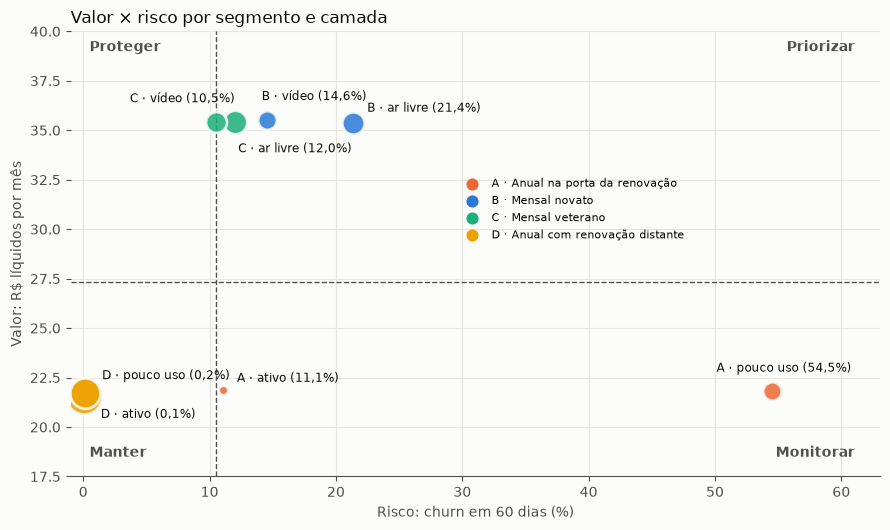

In [6]:
VALOR_BASE = b["valor_mensal_liquido"].mean()
DESLOCA = {"C · vídeo": (-62, 14), "C · ar livre": (2, -22), "B · vídeo": (-4, 14), "B · ar livre": (10, 8),
           "D · ativo": (12, -16), "D · pouco uso": (12, 10), "A · ativo": (10, 6), "A · pouco uso": (-40, 14)}
fig, ax = plt.subplots(figsize=(9, 5.4))
for (s, c), r in camadas.iterrows():
    if r["n"] < 100:
        continue
    rotulo = f"{s[:1]} · {c}"
    ax.scatter(100 * r["churn"], r["valor_mensal"], s=r["n"] / 6, color=COR_SEG[s], alpha=0.85,
               edgecolor=SUPERFICIE, linewidth=2, zorder=3)
    ax.annotate(f"{rotulo} ({pct(r['churn'])})", (100 * r["churn"], r["valor_mensal"]), xytext=DESLOCA.get(rotulo, (8, 6)),
                textcoords="offset points", fontsize=8.5, color=TEXTO)
ax.axvline(100 * CHURN_BASE, color=TEXTO_2, linestyle="--", linewidth=1)
ax.axhline(VALOR_BASE, color=TEXTO_2, linestyle="--", linewidth=1)
x_max = 100 * camadas["churn"].max() * 1.12
for x, y, nome in [(x_max, 39, "Priorizar"), (0.5, 39, "Proteger"), (x_max, 18.5, "Monitorar"), (0.5, 18.5, "Manter")]:
    ax.text(x, y, nome, ha="right" if x > 1 else "left", fontsize=10, color=TEXTO_2, weight="bold")
ax.set_xlim(-1, x_max + 2)
ax.set_ylim(17.5, 40)
ax.set_xlabel("Risco: churn em 60 dias (%)")
ax.set_ylabel("Valor: R$ líquidos por mês")
ax.grid(axis="x", color=GRADE)
ax.set_title("Valor × risco por segmento e camada")
for s in SEGMENTOS:
    ax.scatter([], [], color=COR_SEG[s], s=60, label=s)
ax.legend(frameon=False, fontsize=8, loc="center", bbox_to_anchor=(0.62, 0.6))
fig.tight_layout()
fig.savefig(GRAFICOS / "12_seg_valor_risco.png", dpi=150)
plt.show()

**Leitura.** A matriz da aula coloca o B no quadrante **priorizar** (valor alto, risco acima da média) e o C na fronteira entre proteger e priorizar. O A com pouco uso cai em **monitorar** pela regra do valor mensal, porque o anual deixa R$ 21,80 por mês contra R$ 35,40 do mensal. Mas ele concentra 40% do churn, e a janela de ação é agora: a renovação vence em até 1 mês. Em receita anual em risco, A (R$ 161 mil) e B (R$ 210 mil) são próximos. Por isso, a priorização preliminar soma o valor ao **momento**.

**Agir já (imediato):**
- **A · pouco uso** (1.073);
- **B · ar livre** (1.553);
- **B · vídeo** (1.098).

**Monitorar:**
- **C**, com gatilho de queda de uso ou renovação desligada;
- **D · pouco uso**, para reativar antes da próxima renovação.

**Proteger:**
- **D · ativo**;
- **A · ativo**, com contato leve, sem oferta.

Dentro de qualquer segmento, quem já desligou a renovação sobe para o topo da fila. O teto do CRM (1.500 WhatsApp por mês) cabe no A com pouco uso, mas não em todo o B. A divisão do contato entre canais fica para o plano da semana 10.

## 8. Gravar o segmento de cada assinante

In [7]:
saida = b[["user_id", "segmento", "camada", "cluster", "plano", "meses_ate_renovacao", "renovacao_desligada_ref",
           "valor_mensal_liquido", "churn_60d"]]
saida.to_csv(PROCESSADOS / "segmentos.csv", index=False)
print(f"gravado: dados/processados/segmentos.csv ({len(saida)} linhas)")
display(saida["segmento"].value_counts().reindex(SEGMENTOS))

gravado: dados/processados/segmentos.csv (14032 linhas)


segmento
A · Anual na porta da renovação     1362
B · Mensal novato                   2651
C · Mensal veterano                 3095
D · Anual com renovação distante    6924
Name: count, dtype: int64

**Leitura.** Cada assinante tem segmento e camada em `dados/processados/segmentos.csv`. Esse arquivo alimenta os cartões de persona, o relatório e, na semana 10, o briefing da mensagem gerada por IA. **Limites:**
- O segmento do anual depende da janela de 60 dias: quem está a 2 meses da renovação vira A no mês seguinte. É um segmento de momento, a ser recalculado todo mês.
- A silhueta é fraca (0,23): os grupos são cortes úteis, não tipos naturais de cliente.
- O churn medido inclui o efeito da campanha de agosto (cerca de −1 ponto nos grupos tratados).
- 67% das saídas não têm motivo registrado.